In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Locate project directory
cwd = Path.cwd()
PROJECT_DIR = cwd.parent if cwd.name == "notebooks" else cwd
DATA_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR = PROJECT_DIR / "reports"
OUTPUT_DIR.mkdir(exist_ok=True)

# Load source datasets
nav = pd.read_csv(DATA_DIR / "02_nav_history.csv")
funds = pd.read_csv(DATA_DIR / "01_fund_master.csv")
performance = pd.read_csv(DATA_DIR / "07_scheme_performance.csv")
benchmarks = pd.read_csv(DATA_DIR / "10_benchmark_indices.csv")

# Parse dates and sort
nav["date"] = pd.to_datetime(nav["date"])
benchmarks["date"] = pd.to_datetime(benchmarks["date"])

nav = nav.sort_values(["amfi_code", "date"])
benchmarks = benchmarks.sort_values(["index_name", "date"])

print("NAV rows:", len(nav))
print("Unique funds:", nav["amfi_code"].nunique())
print("Benchmark rows:", len(benchmarks))
print("Fund master rows:", len(funds))
print("Data loaded successfully.")

NAV rows: 46000
Unique funds: 40
Benchmark rows: 8050
Fund master rows: 40
Data loaded successfully.


In [3]:
# Calculate daily returns for all 40 schemes

nav["daily_return"] = (
    nav.groupby("amfi_code")["nav"].pct_change()
)

print("Daily returns calculated.")
print("Total rows:", len(nav))
print("Missing daily returns:", nav["daily_return"].isna().sum())

display(
    nav[["amfi_code", "date", "nav", "daily_return"]].head(10)
)

Daily returns calculated.
Total rows: 46000
Missing daily returns: 40


,amfi_code,date,nav,daily_return
0,100016,2022-01-03,520.4608,NaN
1,100016,2022-01-04,515.0971,-0.010306
2,100016,2022-01-05,521.7239,0.012865
3,100016,2022-01-06,515.7880,-0.011377
4,100016,2022-01-07,515.1639,-0.001210
5,100016,2022-01-10,510.7136,-0.008639
6,100016,2022-01-11,513.5542,0.005562
7,100016,2022-01-12,512.3195,-0.002404
8,100016,2022-01-13,510.2445,-0.004050
9,100016,2022-01-14,514.3636,0.008073


Minimum daily return (%): -5.81
Maximum daily return (%): 6.47
Mean daily return (%): 0.0631
Median daily return (%): 0.034


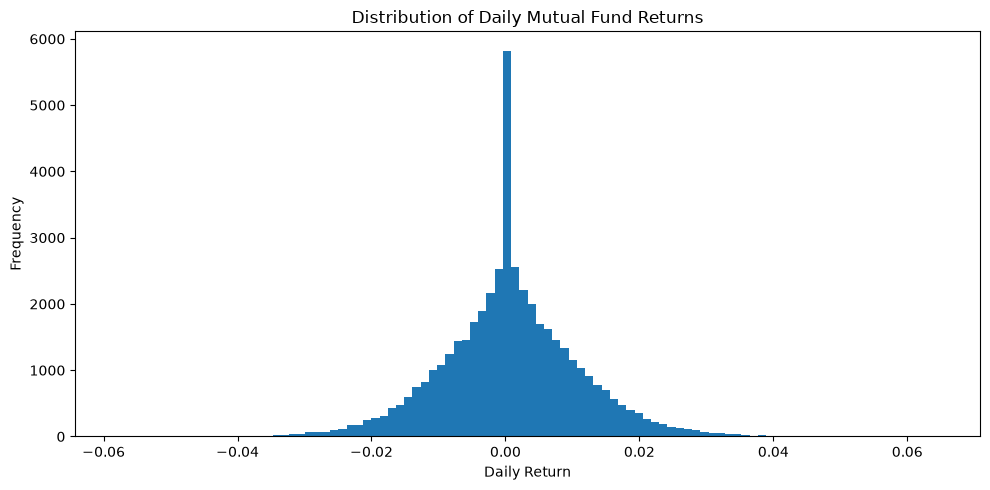

In [4]:
# Validate daily return distribution

daily_returns = nav["daily_return"].dropna()

print("Minimum daily return (%):", round(daily_returns.min() * 100, 2))
print("Maximum daily return (%):", round(daily_returns.max() * 100, 2))
print("Mean daily return (%):", round(daily_returns.mean() * 100, 4))
print("Median daily return (%):", round(daily_returns.median() * 100, 4))

plt.figure(figsize=(10, 5))
plt.hist(daily_returns, bins=100)
plt.title("Distribution of Daily Mutual Fund Returns")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [5]:
# Calculate 1-year, 3-year and 5-year CAGR for all funds

def calculate_cagr(group, years):
    group = group.sort_values("date")
    end_date = group["date"].max()
    target_date = end_date - pd.DateOffset(years=years)

    eligible = group[group["date"] <= target_date]

    if eligible.empty:
        return np.nan

    start_row = eligible.iloc[-1]
    end_row = group.iloc[-1]

    # Use actual trading-day observations for annualisation
    start_idx = group.index.get_loc(start_row.name)
    end_idx = group.index.get_loc(end_row.name)
    trading_days = end_idx - start_idx

    if trading_days <= 0 or start_row["nav"] <= 0:
        return np.nan

    return (
        (end_row["nav"] / start_row["nav"]) ** (252 / trading_days) - 1
    ) * 100


cagr_rows = []

for amfi_code, group in nav.groupby("amfi_code"):
    cagr_rows.append({
        "amfi_code": amfi_code,
        "cagr_1yr_pct": calculate_cagr(group, 1),
        "cagr_3yr_pct": calculate_cagr(group, 3),
        "cagr_5yr_pct": calculate_cagr(group, 5),
    })

cagr_df = pd.DataFrame(cagr_rows)

display(cagr_df.head(10))

print("Total funds:", len(cagr_df))
print("Funds with 1-year CAGR:", cagr_df["cagr_1yr_pct"].notna().sum())
print("Funds with 3-year CAGR:", cagr_df["cagr_3yr_pct"].notna().sum())
print("Funds with 5-year CAGR:", cagr_df["cagr_5yr_pct"].notna().sum())

,amfi_code,cagr_1yr_pct,cagr_3yr_pct,cagr_5yr_pct
0,100016,-2.148402,1.246197,NaN
1,100025,3.574955,3.773913,NaN
2,100033,50.993827,31.120055,NaN
3,101206,45.940417,27.801276,NaN
4,101207,-23.263758,-4.007094,NaN
5,101208,6.978598,6.083497,NaN
6,102885,19.447212,18.902373,NaN
7,102886,-16.268207,-0.740101,NaN
8,102887,13.085384,24.539807,NaN
9,118632,32.636351,21.761198,NaN


Total funds: 40
Funds with 1-year CAGR: 40
Funds with 3-year CAGR: 40
Funds with 5-year CAGR: 0


In [6]:
# Calculate Sharpe and Sortino ratios for each fund

RISK_FREE_RATE = 0.065

risk_rows = []

for amfi_code, group in nav.groupby("amfi_code"):
    returns = group["daily_return"].dropna()

    if len(returns) < 2:
        continue

    annual_return = returns.mean() * 252
    annual_volatility = returns.std() * np.sqrt(252)

    sharpe = (
        (annual_return - RISK_FREE_RATE) / annual_volatility
        if annual_volatility > 0 else np.nan
    )

    downside_returns = returns[returns < 0]
    downside_deviation = (
        np.sqrt((downside_returns ** 2).mean()) * np.sqrt(252)
        if len(downside_returns) > 0 else np.nan
    )

    sortino = (
        (annual_return - RISK_FREE_RATE) / downside_deviation
        if downside_deviation and downside_deviation > 0 else np.nan
    )

    risk_rows.append({
        "amfi_code": amfi_code,
        "annualized_return_pct": annual_return * 100,
        "annualized_volatility_pct": annual_volatility * 100,
        "sharpe_ratio": sharpe,
        "sortino_ratio": sortino
    })

risk_df = pd.DataFrame(risk_rows)

display(risk_df.head(10))

print("Funds analysed:", len(risk_df))
print("Missing Sharpe ratios:", risk_df["sharpe_ratio"].isna().sum())
print("Missing Sortino ratios:", risk_df["sortino_ratio"].isna().sum())

,amfi_code,annualized_return_pct,annualized_volatility_pct,sharpe_ratio,sortino_ratio
0,100016,3.568303,14.548135,-0.201517,-0.208477
1,100025,4.285356,3.905246,-0.567095,-0.587360
2,100033,27.211057,18.936711,1.093699,1.136584
3,101206,21.464662,14.568213,1.027213,1.083847
4,101207,10.696212,25.797322,0.162661,0.166070
5,101208,6.086966,0.506437,-0.815567,-1.086270
6,102885,16.988801,12.836628,0.817099,0.852124
7,102886,2.767331,18.134576,-0.205832,-0.203717
8,102887,16.262585,15.758367,0.619518,0.653772
9,118632,21.803695,14.148352,1.081659,1.123303


Funds analysed: 40
Missing Sharpe ratios: 0
Missing Sortino ratios: 0


In [7]:
# Inspect available benchmark indices

print(benchmarks["index_name"].value_counts())

display(benchmarks.head())

index_name
BSE_SMALLCAP       1150
CRISIL_GILT        1150
CRISIL_LIQUID      1150
NIFTY100           1150
NIFTY50            1150
NIFTY500           1150
NIFTY_MIDCAP150    1150
Name: count, dtype: int64


,date,index_name,close_value
3450,2022-01-03,BSE_SMALLCAP,26554.60
3451,2022-01-04,BSE_SMALLCAP,27079.92
3452,2022-01-05,BSE_SMALLCAP,27313.35
3453,2022-01-06,BSE_SMALLCAP,27377.05
3454,2022-01-07,BSE_SMALLCAP,26316.86


In [8]:
from scipy.stats import linregress

# Prepare NIFTY100 daily returns
nifty = benchmarks[
    benchmarks["index_name"] == "NIFTY100"
][["date", "close_value"]].copy()

nifty = nifty.sort_values("date")
nifty["benchmark_return"] = nifty["close_value"].pct_change()

alpha_beta_rows = []
drawdown_rows = []

for amfi_code, group in nav.groupby("amfi_code"):
    group = group.sort_values("date").copy()

    # Maximum drawdown
    group["running_max"] = group["nav"].cummax()
    group["drawdown"] = group["nav"] / group["running_max"] - 1

    worst_idx = group["drawdown"].idxmin()
    worst_row = group.loc[worst_idx]

    drawdown_rows.append({
        "amfi_code": amfi_code,
        "max_drawdown_pct": group["drawdown"].min() * 100,
        "max_drawdown_date": worst_row["date"],
        "nav_at_max_drawdown": worst_row["nav"],
        "previous_peak_nav": worst_row["running_max"]
    })

    # Match fund and benchmark returns by date
    merged = group[["date", "daily_return"]].merge(
        nifty[["date", "benchmark_return"]],
        on="date",
        how="inner"
    ).dropna()

    if len(merged) < 30:
        continue

    result = linregress(
        merged["benchmark_return"],
        merged["daily_return"]
    )

    alpha_daily = result.intercept
    beta = result.slope

    alpha_beta_rows.append({
        "amfi_code": amfi_code,
        "alpha_annualized_pct": alpha_daily * 252 * 100,
        "beta": beta,
        "r_squared": result.rvalue ** 2,
        "observations": len(merged)
    })

alpha_beta_df = pd.DataFrame(alpha_beta_rows)
drawdown_df = pd.DataFrame(drawdown_rows)

print("Alpha/Beta funds:", len(alpha_beta_df))
print("Drawdown funds:", len(drawdown_df))

display(alpha_beta_df.head())
display(drawdown_df.head())

Alpha/Beta funds: 40
Drawdown funds: 40


,amfi_code,alpha_annualized_pct,beta,r_squared,observations
0,100016,3.747581,-0.058268,0.002665,1149
1,100025,4.281792,0.001158,0.000015,1149
2,100033,27.195355,0.005104,0.000012,1149
3,101206,21.399785,0.021086,0.000348,1149
4,101207,10.897092,-0.065289,0.001064,1149


,amfi_code,max_drawdown_pct,max_drawdown_date,nav_at_max_drawdown,previous_peak_nav
0,100016,-24.734441,2022-09-15,411.1759,546.3002
1,100025,-4.308264,2023-07-28,27.5108,28.7494
2,100033,-16.217209,2022-05-12,93.5553,111.6641
3,101206,-11.291596,2023-07-05,328.2234,370.0026
4,101207,-35.446916,2026-05-11,51.8695,80.3517


In [9]:
# Combine all calculated metrics
scorecard = (
    funds[["amfi_code", "scheme_name", "fund_house", "category"]]
    .merge(cagr_df, on="amfi_code", how="left")
    .merge(risk_df, on="amfi_code", how="left")
    .merge(alpha_beta_df, on="amfi_code", how="left")
    .merge(drawdown_df, on="amfi_code", how="left")
)

# Export Alpha and Beta results
alpha_beta_df.merge(
    funds[["amfi_code", "scheme_name", "fund_house"]],
    on="amfi_code",
    how="left"
).to_csv(OUTPUT_DIR / "alpha_beta.csv", index=False)

# Convert metric rankings to a 0–100 percentile scale
scorecard["return_rank"] = scorecard["cagr_3yr_pct"].rank(pct=True) * 100
scorecard["sharpe_rank"] = scorecard["sharpe_ratio"].rank(pct=True) * 100
scorecard["alpha_rank"] = scorecard["alpha_annualized_pct"].rank(pct=True) * 100
scorecard["expense_rank"] = (
    scorecard["expense_ratio_pct"].rank(ascending=False, pct=True) * 100
)
scorecard["drawdown_rank"] = (
    scorecard["max_drawdown_pct"].rank(pct=True) * 100
)

# Weighted scorecard
scorecard["fund_score"] = (
    0.30 * scorecard["return_rank"]
    + 0.25 * scorecard["sharpe_rank"]
    + 0.20 * scorecard["alpha_rank"]
    + 0.15 * scorecard["expense_rank"]
    + 0.10 * scorecard["drawdown_rank"]
)

scorecard = scorecard.sort_values("fund_score", ascending=False)

scorecard.to_csv(OUTPUT_DIR / "fund_scorecard.csv", index=False)

print("Files generated:")
print(OUTPUT_DIR / "alpha_beta.csv")
print(OUTPUT_DIR / "fund_scorecard.csv")

display(
    scorecard[
        ["scheme_name", "cagr_3yr_pct", "sharpe_ratio",
         "alpha_annualized_pct", "max_drawdown_pct", "fund_score"]
    ].head(10)
)

KeyError: 'expense_ratio_pct'

In [10]:
# ============================================
# FUND SCORECARD + ALPHA/BETA CSV EXPORT
# ============================================

import pandas as pd
import numpy as np
from pathlib import Path

# 1. Ensure output folder exists
cwd = Path.cwd()
PROJECT_DIR = cwd.parent if cwd.name == "notebooks" else cwd
OUTPUT_DIR = PROJECT_DIR / "reports"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 2. Load expense ratio from performance dataset
expense_data = performance[
    ["amfi_code", "expense_ratio_pct"]
].drop_duplicates("amfi_code")

# 3. Prepare fund details
fund_details = funds[
    ["amfi_code", "scheme_name", "fund_house", "category"]
].drop_duplicates("amfi_code")

# 4. Combine all metrics
scorecard = (
    fund_details
    .merge(cagr_df, on="amfi_code", how="left")
    .merge(risk_df, on="amfi_code", how="left")
    .merge(alpha_beta_df, on="amfi_code", how="left")
    .merge(drawdown_df, on="amfi_code", how="left")
    .merge(expense_data, on="amfi_code", how="left")
)

# 5. Create percentile rankings
# Higher 3-year CAGR, Sharpe and Alpha are better.
# Lower expense ratio and less severe drawdown are better.

scorecard["return_rank"] = (
    scorecard["cagr_3yr_pct"].rank(pct=True) * 100
)

scorecard["sharpe_rank"] = (
    scorecard["sharpe_ratio"].rank(pct=True) * 100
)

scorecard["alpha_rank"] = (
    scorecard["alpha_annualized_pct"].rank(pct=True) * 100
)

scorecard["expense_rank"] = (
    scorecard["expense_ratio_pct"]
    .rank(ascending=False, pct=True) * 100
)

scorecard["drawdown_rank"] = (
    scorecard["max_drawdown_pct"].rank(pct=True) * 100
)

# 6. Weighted fund score
scorecard["fund_score"] = (
    0.30 * scorecard["return_rank"]
    + 0.25 * scorecard["sharpe_rank"]
    + 0.20 * scorecard["alpha_rank"]
    + 0.15 * scorecard["expense_rank"]
    + 0.10 * scorecard["drawdown_rank"]
)

# 7. Sort funds by score
scorecard = scorecard.sort_values(
    "fund_score", ascending=False
).reset_index(drop=True)

# 8. Export Alpha/Beta file with fund names
alpha_beta_export = alpha_beta_df.merge(
    fund_details[["amfi_code", "scheme_name", "fund_house"]],
    on="amfi_code",
    how="left"
)

alpha_beta_export.to_csv(
    OUTPUT_DIR / "alpha_beta.csv",
    index=False
)

# 9. Export fund scorecard
scorecard.to_csv(
    OUTPUT_DIR / "fund_scorecard.csv",
    index=False
)

# 10. Verify exported deliverables
print("EXPORT COMPLETE")
print("-" * 45)
print("Alpha/Beta file:", OUTPUT_DIR / "alpha_beta.csv")
print("Fund scorecard:", OUTPUT_DIR / "fund_scorecard.csv")
print()
print("Scorecard rows:", len(scorecard))
print("Alpha/Beta rows:", len(alpha_beta_export))
print("Missing expense ratios:", scorecard["expense_ratio_pct"].isna().sum())
print("Missing 3-year CAGR:", scorecard["cagr_3yr_pct"].isna().sum())

display(
    scorecard[
        [
            "scheme_name",
            "cagr_3yr_pct",
            "sharpe_ratio",
            "sortino_ratio",
            "alpha_annualized_pct",
            "beta",
            "max_drawdown_pct",
            "expense_ratio_pct",
            "fund_score"
        ]
    ].head(10)
)

EXPORT COMPLETE
---------------------------------------------
Alpha/Beta file: c:\Users\ishar\OneDrive\Documents\MF-Analytics-Platform\reports\alpha_beta.csv
Fund scorecard: c:\Users\ishar\OneDrive\Documents\MF-Analytics-Platform\reports\fund_scorecard.csv

Scorecard rows: 40
Alpha/Beta rows: 40
Missing expense ratios: 0
Missing 3-year CAGR: 0


,scheme_name,cagr_3yr_pct,sharpe_ratio,sortino_ratio,alpha_annualized_pct,beta,max_drawdown_pct,expense_ratio_pct,fund_score
0,Mirae Asset Large Cap Fund - Regular - Growth,32.607536,1.448291,1.478908,26.983751,0.023684,-11.265729,1.46,86.2500
1,ICICI Pru Midcap Fund - Regular - Growth,30.485224,1.180101,1.243215,29.263583,0.000549,-18.188514,1.36,82.2500
2,Kotak Flexicap Fund - Regular - Growth,28.388970,1.306744,1.405006,27.330465,-0.022830,-12.973968,1.45,82.0000
3,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,31.120055,1.093699,1.136584,27.195355,0.005104,-16.217209,1.38,80.7500
4,ICICI Pru Bluechip Fund - Direct - Growth,31.162984,1.026524,1.057136,21.194827,0.016232,-12.588276,0.80,80.0000
5,Axis Midcap Fund - Regular - Growth,33.667452,0.998231,1.062037,26.076669,-0.066265,-20.960884,1.38,77.0000
6,SBI Bluechip Fund - Regular Plan - Growth,29.223656,1.208267,1.266908,23.201007,-0.031751,-15.012385,1.54,74.8125
7,Mirae Asset Tax Saver Fund - Regular - Growth,28.003092,1.234930,1.316805,28.270368,0.018134,-16.396743,1.60,73.6875
8,ABSL Frontline Equity Fund - Regular - Growth,27.801276,1.027213,1.083847,21.399785,0.021086,-11.291596,1.60,68.1875
9,SBI Small Cap Fund - Regular Plan - Growth,25.604903,0.945308,0.991028,30.336965,-0.023196,-28.706006,1.43,67.3750


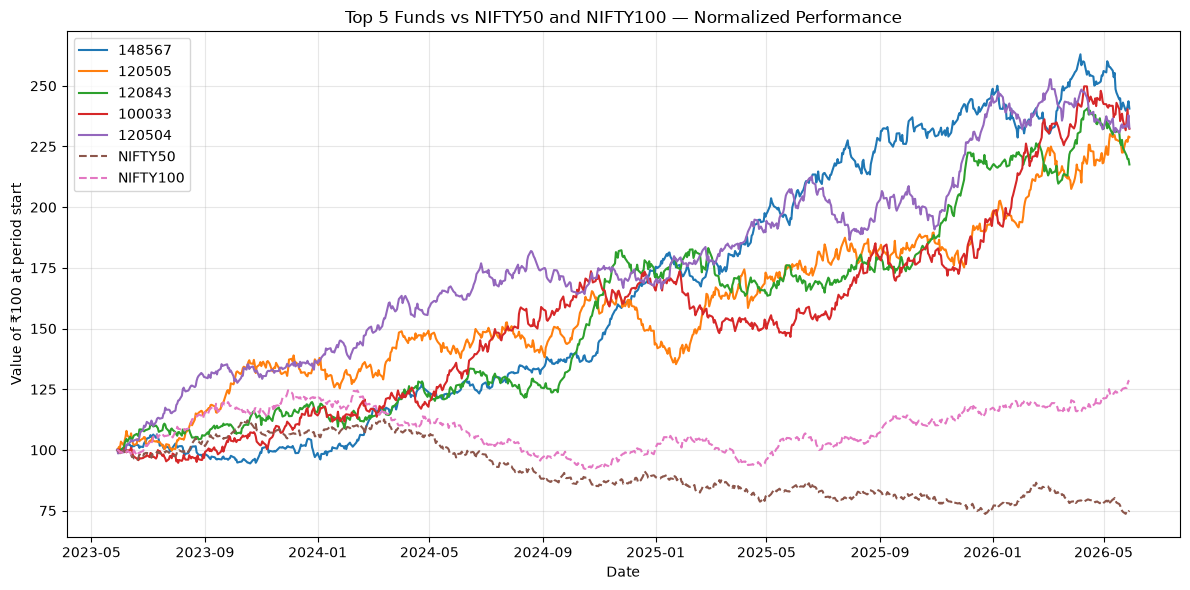

Chart saved: c:\Users\ishar\OneDrive\Documents\MF-Analytics-Platform\reports\benchmark_comparison.png


In [11]:
# Compare top 5 funds with NIFTY50 and NIFTY100 over 3 years

import matplotlib.pyplot as plt
import pandas as pd

top5 = scorecard.head(5)["amfi_code"].astype(str).tolist()

nav["amfi_code"] = nav["amfi_code"].astype(str)

# Use a common date range of approximately 3 years
end_date = nav["date"].max()
start_date = end_date - pd.DateOffset(years=3)

plt.figure(figsize=(12, 6))

for code in top5:
    fund_data = nav[
        (nav["amfi_code"] == code) &
        (nav["date"] >= start_date)
    ].sort_values("date")

    if not fund_data.empty:
        normalized = fund_data["nav"] / fund_data["nav"].iloc[0] * 100
        plt.plot(
            fund_data["date"],
            normalized,
            label=fund_data["amfi_code"].iloc[0]
        )

for index_name in ["NIFTY50", "NIFTY100"]:
    benchmark_data = benchmarks[
        (benchmarks["index_name"] == index_name) &
        (benchmarks["date"] >= start_date)
    ].sort_values("date")

    if not benchmark_data.empty:
        normalized = (
            benchmark_data["close_value"] /
            benchmark_data["close_value"].iloc[0] * 100
        )

        plt.plot(
            benchmark_data["date"],
            normalized,
            linestyle="--",
            label=index_name
        )

plt.title("Top 5 Funds vs NIFTY50 and NIFTY100 — Normalized Performance")
plt.xlabel("Date")
plt.ylabel("Value of ₹100 at period start")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

chart_path = OUTPUT_DIR / "benchmark_comparison.png"
plt.savefig(chart_path, dpi=200, bbox_inches="tight")
plt.show()

print("Chart saved:", chart_path)